Verify that your dataset is generated correctly

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATASET_LOCATION = "..\\data\\synthetic\\synthetic_fmri.csv"
# Load dataset
data = pd.read_csv(DATASET_LOCATION)

# Display first five rows
print(data.head())

   timepoint  time_seconds      ROI_01      ROI_02      ROI_03      ROI_04  \
0          1           0.0  100.770632   99.015117  100.779769  101.107240   
1          2           2.0   99.227586   99.216072   99.226181   98.990184   
2          3           4.0   99.265926  100.391654   97.841793   99.442875   
3          4           6.0   98.916295   99.523603  100.318231   99.640256   
4          5           8.0   99.538742  100.660557  100.335065   98.911886   

       ROI_05      ROI_06      ROI_07     ROI_08      ROI_09      ROI_10  
0  100.240055   99.898524  100.419728  97.486536  100.326288   99.944779  
1   98.887018   99.237145   99.180187  97.980099   99.818444   98.387851  
2   98.524798   99.169381   98.447060  98.626775  100.854612   98.021008  
3   99.383309   99.537385   98.650551  99.361621  102.523408  100.241579  
4  101.215224  101.061821  100.830974  99.737279  102.043634  101.127794  


In [7]:
# Dataset dimensions
print("Dataset shape:", data.shape)

Dataset shape: (300, 12)


In [8]:
# Check missing values
print(data.isnull().sum())

timepoint       0
time_seconds    0
ROI_01          0
ROI_02          0
ROI_03          0
ROI_04          0
ROI_05          0
ROI_06          0
ROI_07          0
ROI_08          0
ROI_09          0
ROI_10          0
dtype: int64


In [9]:
# Extract ROI columns
roi_data = data.filter(regex="^ROI_")

In [10]:
print("ROI matrix shape:", roi_data.shape)

ROI matrix shape: (300, 10)


In [11]:
# Statistical summary
print(roi_data.describe())

           ROI_01      ROI_02      ROI_03      ROI_04      ROI_05      ROI_06  \
count  300.000000  300.000000  300.000000  300.000000  300.000000  300.000000   
mean   100.178839   99.912879  100.088797   99.831851  100.241891   99.810792   
std      1.499349    1.529499    1.472169    1.466663    1.453303    1.519629   
min     95.976513   96.045652   95.555180   94.584436   95.955252   95.801912   
25%     99.219277   98.894563   99.112563   98.907417   99.312043   98.757140   
50%    100.247567   99.939607  100.064062   99.822738  100.256680   99.869334   
75%    101.147215  100.951379  101.215046  100.834408  101.218572  100.848420   
max    105.302124  104.301924  104.026848  103.651687  103.662591  103.618188   

           ROI_07      ROI_08      ROI_09      ROI_10  
count  300.000000  300.000000  300.000000  300.000000  
mean    99.985794   99.954080  100.136035   99.854934  
std      1.572138    1.455070    1.434725    1.476477  
min     94.750557   95.349914   95.848788   93

Visualize the ROI signals

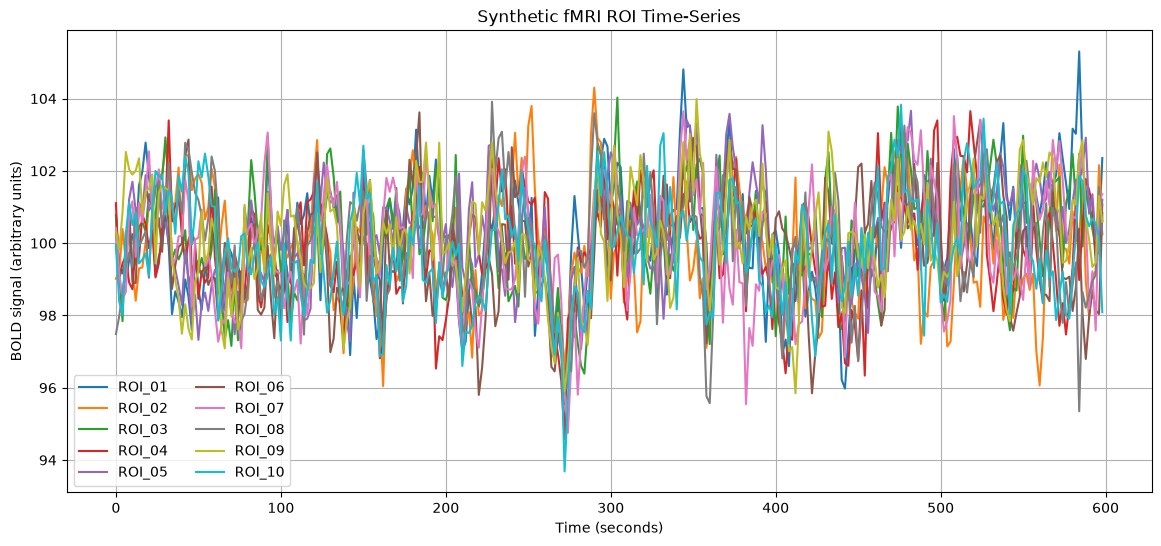

In [12]:
plt.figure(figsize=(14, 6))

for column in roi_data.columns:
    plt.plot(
        data["time_seconds"],
        roi_data[column],
        label=column
    )

plt.xlabel("Time (seconds)")
plt.ylabel("BOLD signal (arbitrary units)")
plt.title("Synthetic fMRI ROI Time-Series")

plt.legend(ncol=2)
plt.grid()
plt.show()

Visualizing individual brain regions

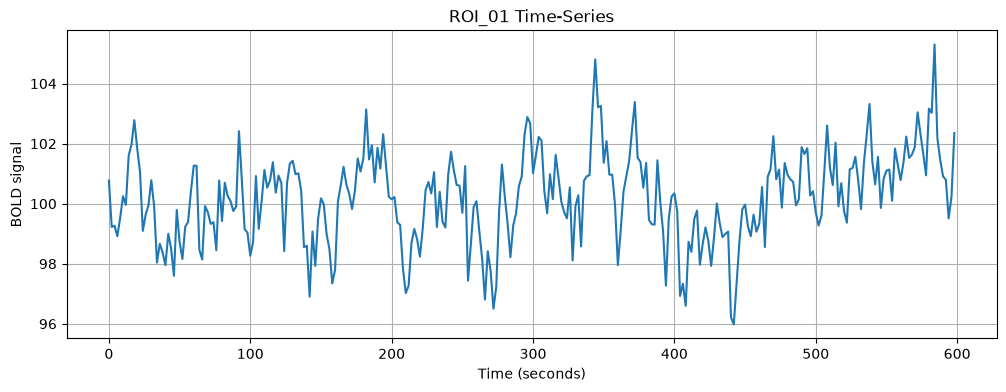

In [14]:
ROI = "ROI_01"

plt.figure(figsize=(12, 4))

plt.plot(
    data["time_seconds"],
    data[ROI]
)

plt.xlabel("Time (seconds)")
plt.ylabel("BOLD signal")
plt.title(f"{ROI} Time-Series")
plt.grid()

plt.show()

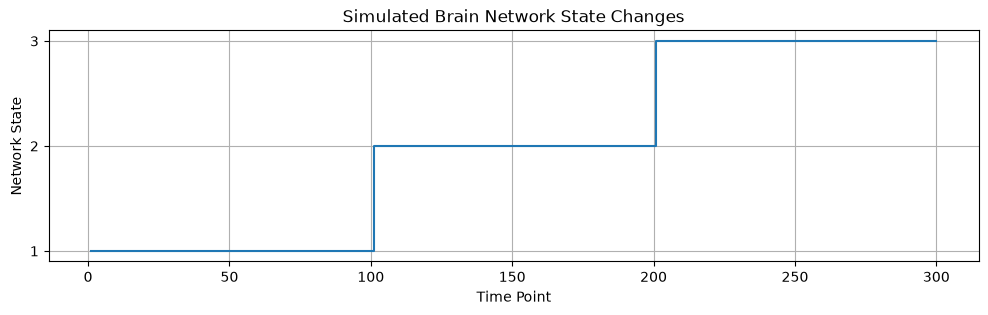

In [15]:
truth = pd.read_csv(
    "../data/synthetic/synthetic_ground_truth.csv"
)

plt.figure(figsize=(12, 3))

plt.step(
    truth["timepoint"],
    truth["simulated_state"].str[-1].astype(int),
    where="post"
)

plt.xlabel("Time Point")
plt.ylabel("Network State")
plt.title("Simulated Brain Network State Changes")

plt.yticks([1, 2, 3])
plt.grid()

plt.show()